# Mini-Projet : Prédiction du prix des ordinateurs portables
## Étape 1 : Chargement et exploration des données

In [1]:
import pandas as pd

# Chargement du dataset
data = pd.read_csv('laptop_price.csv')

# Affichage des 5 premières lignes
print(data.head())
print(data.info())

   Unnamed: 0.1  Unnamed: 0   brand                                  name  \
0             0           0      HP      Victus 15-fb0157AX Gaming Laptop   
1             1           1      HP                   15s-fq5007TU Laptop   
2             2           2    Acer                  One 14 Z8-415 Laptop   
3             3           3  Lenovo  Yoga Slim 6 14IAP8 82WU0095IN Laptop   
4             4           4   Apple       MacBook Air 2020 MGND3HN Laptop   

   price  spec_rating                      processor  \
0  49900    73.000000      5th Gen AMD Ryzen 5 5600H   
1  39900    60.000000   12th Gen Intel Core i3 1215U   
2  26990    69.323529  11th Gen Intel Core i3 1115G4   
3  59729    66.000000   12th Gen Intel Core i5 1240P   
4  69990    69.323529                       Apple M1   

                              CPU   Ram Ram_type    ROM ROM_type  \
0           Hexa Core, 12 Threads   8GB     DDR4  512GB      SSD   
1  Hexa Core (2P + 4E), 8 Threads   8GB     DDR4  512GB      SSD

## Étape 2 : Nettoyage et Prétraitement
Pour que nos modèles puissent apprendre, nous devons :
1. Supprimer les colonnes inutiles (comme l'index ou le nom exact du PC qui est trop spécifique).
2. Transformer les colonnes de texte comme la RAM ("8GB") ou le disque dur ("512GB", "1TB") en valeurs purement numériques.

In [ ]:
data = data.drop(['Unnamed: 0', 'name'], axis=1)

# Nettoyage de la colonne 'Ram' (enlever 'GB' et convertir en entier)
data['Ram'] = data['Ram'].str.replace('GB', '').astype(int)

# Nettoyage de la colonne 'ROM' 
# On convertit d'abord les Téraoctets en Gigaoctets, puis on retire 'GB'
data['ROM'] = data['ROM'].str.replace('1TB', '1024')
data['ROM'] = data['ROM'].str.replace('2TB', '2048')
data['ROM'] = data['ROM'].str.replace('GB', '').astype(float)

# Vérification du résultat
print(data[['brand', 'Ram', 'ROM', 'price']].head())

    brand  Ram    ROM  price
0      HP    8  512.0  49900
1      HP    8  512.0  39900
2    Acer    8  512.0  26990
3  Lenovo   16  512.0  59729
4   Apple    8  256.0  69990


## Étape 3 : Encodage des variables catégorielles

In [3]:
from sklearn.preprocessing import LabelEncoder

# On sélectionne les colonnes de texte (catégorielles) à encoder
colonnes_texte = ['brand', 'processor', 'CPU', 'Ram_type', 'ROM_type', 'GPU', 'OS']

le = LabelEncoder()

# On boucle sur ces colonnes pour les encoder
for col in colonnes_texte:
    data[col] = le.fit_transform(data[col].astype(str))

print("Aperçu après encodage :")
print(data[['brand', 'processor', 'OS', 'price']].head())

Aperçu après encodage :
   brand  processor  OS  price
0      9        105  12  49900
1      9         34  12  39900
2      1         15  12  26990
3     14         39  12  59729
4      2        160   7  69990


## Étape 4 : Séparation des données

In [4]:
from sklearn.model_selection import train_test_split

# On sépare nos features (X) de notre cible (y)
X = data.drop('price', axis=1) # On garde tout sauf le prix
y = data['price']              # On veut prédire le prix

# Division 80% entraînement / 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Taille X_train :", X_train.shape)
print("Taille X_test :", X_test.shape)

Taille X_train : (714, 15)
Taille X_test : (179, 15)


## Étape 5 et 6 : Comparaison des modèles et Évaluation
Nous allons comparer deux algorithmes pour prédire le prix :
1. **Régression Linéaire** : Modèle simple.
2. **Random Forest (Forêt Aléatoire)** : Modèle complexe capable de capturer des relations non linéaires (ex: la marque "Apple" augmente le prix indépendamment de la RAM).

RÉGRESSION LINÉAIRE
MAE  : 19007.364982197912
RMSE : 27070.92551971124
R²   : 0.7861362654222233

 RANDOM FOREST 
MAE  : 13031.013910614527
RMSE : 22653.644531449947
R²   : 0.8502361136398089


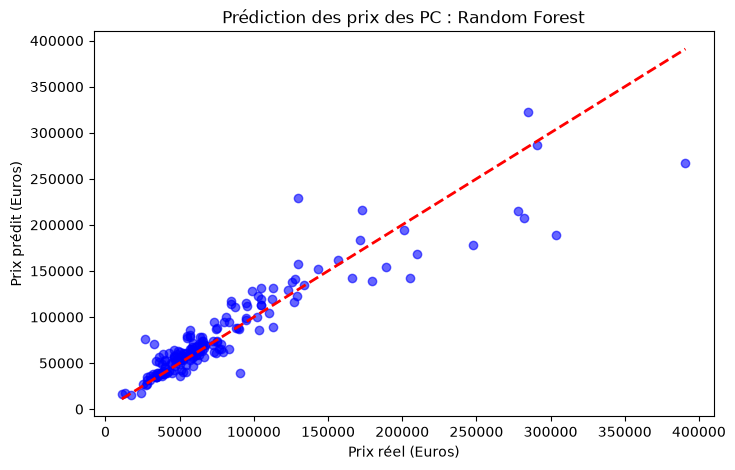

In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Régression Linéaire 
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)

# Random Forest
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

# Évaluation et Comparaison ---
print("RÉGRESSION LINÉAIRE")
print("MAE  :", mean_absolute_error(y_test, y_pred_lr))
print("RMSE :", np.sqrt(mean_squared_error(y_test, y_pred_lr)))
print("R²   :", r2_score(y_test, y_pred_lr))

print("\n RANDOM FOREST ")
print("MAE  :", mean_absolute_error(y_test, y_pred_rf))
print("RMSE :", np.sqrt(mean_squared_error(y_test, y_pred_rf)))
print("R²   :", r2_score(y_test, y_pred_rf))

# Visualisation des résultats
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred_rf, alpha=0.6, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2) # Ligne parfaite
plt.xlabel("Prix réel (Euros)")
plt.ylabel("Prix prédit (Euros)")
plt.title("Prédiction des prix des PC : Random Forest")
plt.show()

### Conclusion et Interprétation des Résultats

Suite à l'entraînement et à l'évaluation de nos deux modèles sur le dataset des prix d'ordinateurs portables, voici notre analyse comparative :

**1. Comparaison des performances (Score R²)**
* La **Régression Linéaire** obtient un score R² d'environ **0.78**. Elle parvient à expliquer 78% de la variance des prix, ce qui est un score correct, mais qui montre les limites d'une approche purement proportionnelle.
* Le **Random Forest** la surpasse largement avec un score R² de **0.85**. Il réussit à capturer 85% des variations complexes du prix des PC.

**2. Analyse des erreurs (MAE et RMSE)**
* L'Erreur Absolue Moyenne (MAE) passe d'environ 19 007 avec le modèle linéaire à **13 031** avec le Random Forest (ces valeurs sont exprimées dans la monnaie d'origine du dataset, probablement des Roupies indiennes vu l'ordre de grandeur). Le Random Forest se trompe donc beaucoup moins dans ses estimations au quotidien.

**3. Justification technique**
* Le prix d'un ordinateur n'évolue pas de manière strictement linéaire. Par exemple, le passage de 8 Go à 16 Go de RAM ne coûte pas la même chose selon qu'il s'agisse d'un PC Acer ou d'un MacBook. Il existe une forte "prime de marque" et des synergies entre les composants (un processeur i9 n'a de valeur que s'il est couplé à une bonne carte graphique).
* La Régression Linéaire échoue à capter ces nuances. À l'inverse, le Random Forest, grâce à ses multiples arbres de décision, isole parfaitement ces règles conditionnelles non-linéaires.

